<a href="https://colab.research.google.com/github/Dev-Mowlid/Adventurer/blob/master/%20Zindi%20Financial%20Inclusion%20in%20Africa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import files

In [ ]:
train = pd.read_csv("Train.csv")
test = pd.read_csv("Test.csv")
definitions = pd.read_csv("VariableDefinitions.csv")
ss = pd.read_csv("SampleSubmission.csv")

In [ ]:
display(train.head())

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [ ]:
display(definitions)

,Variable Definitions,Unnamed: 1
0,country,Country interviewee is in.
1,year,Year survey was done in.
2,uniqueid,Unique identifier for each interviewee
3,location_type,"Type of location: Rural, Urban"
4,cellphone_access,"If interviewee has access to a cellphone: Yes, No"
5,household_size,Number of people living in one house
6,age_of_respondent,The age of the interviewee
7,gender_of_respondent,"Gender of interviewee: Male, Female"
8,relationship_with_head,The interviewee’s relationship with the head o...
9,marital_status,The martial status of the interviewee: Married...


In [ ]:
display(train.shape)

(23524, 13)

In [ ]:
print(train.isnull().sum())

country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
dtype: int64


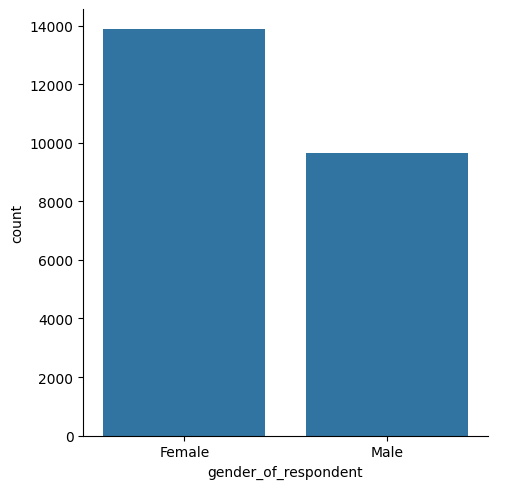

In [ ]:
sns.catplot(x="gender_of_respondent", kind="count", data=train)

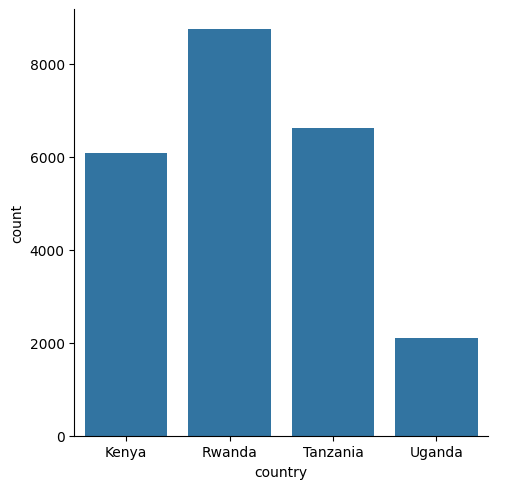

In [ ]:
sns.catplot(x="country", kind="count", data=train)

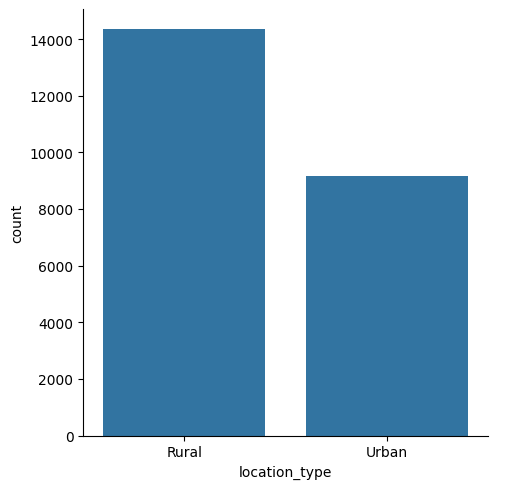

In [ ]:
sns.catplot(x="location_type", kind="count", data=train)

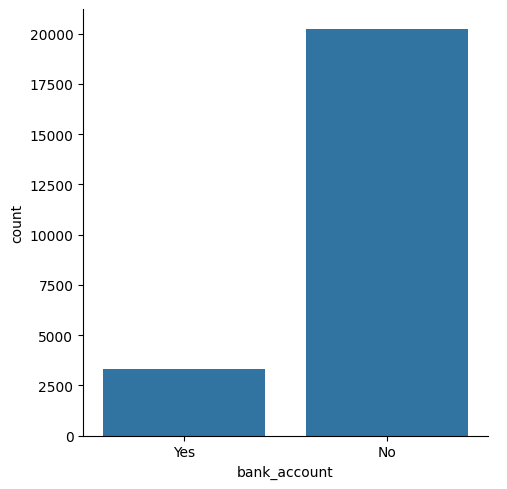

In [ ]:
sns.catplot(x="bank_account", kind="count", data=train)

In [ ]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   country                 23524 non-null  object
 1   year                    23524 non-null  int64 
 2   uniqueid                23524 non-null  object
 3   bank_account            23524 non-null  object
 4   location_type           23524 non-null  object
 5   cellphone_access        23524 non-null  object
 6   household_size          23524 non-null  int64 
 7   age_of_respondent       23524 non-null  int64 
 8   gender_of_respondent    23524 non-null  object
 9   relationship_with_head  23524 non-null  object
 10  marital_status          23524 non-null  object
 11  education_level         23524 non-null  object
 12  job_type                23524 non-null  object
dtypes: int64(3), object(10)
memory usage: 2.3+ MB
None


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

le = LabelEncoder()

In [ ]:
train['bank_account'] = le.fit_transform(train['bank_account'])

x_train = train.drop(['bank_account'],axis=1)

print(train.shape)
print(x_train.shape)

y_train = train['bank_account']
print(y_train.shape)


(23524, 13)
(23524, 12)
(23524,)


In [ ]:
print(y_train.shape)

(23524,)


In [ ]:
display(x_train.head())

,country,year,uniqueid,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [ ]:
display(y_train)

,bank_account
0,1
1,0
2,1
3,0
4,0
...,...
23519,0
23520,0
23521,0
23522,0


In [ ]:
print(x_train.shape)

(23524, 12)


In [ ]:
def preprocessing_data(data):

  float_columns = data[['year','age_of_respondent','household_size']].values.astype(float)

  cate = ['job_type','education_level','marital_status','country','relationship_with_head']

  data = pd.get_dummies(data, prefix="_", columns=cate)


  data['cellphone_access'] = le.fit_transform(data['cellphone_access'])
  data['location_type'] = le.fit_transform(data['location_type'])
  data['gender_of_respondent'] = le.fit_transform(data['gender_of_respondent'])

  data = data.drop(['uniqueid'], axis=1)

  scaler = MinMaxScaler(feature_range=(0,1))
  data = scaler.fit_transform(data)
  return data

In [ ]:
processed_train = preprocessing_data(x_train)
processed_test = preprocessing_data(test)

In [ ]:
print(processed_train.shape)

(23524, 37)


In [ ]:
import sklearn.model_selection
from sklearn.model_selection import train_test_split


x_train , x_val , y_train, y_val = train_test_split(processed_train, y_train,stratify=y_train, test_size=0.1, random_state=42)

In [ ]:
from xgboost import XGBClassifier

xg_model = XGBClassifier()

xg_model.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score


xg_y_model = xg_model.predict(x_val)

print(f"error rate xgb classifier,", 1-accuracy_score(y_val,xg_y_model))

error rate xgb classifier, 0.11219719507012327


[[0.96686449 0.03313551]
 [0.59516616 0.40483384]]


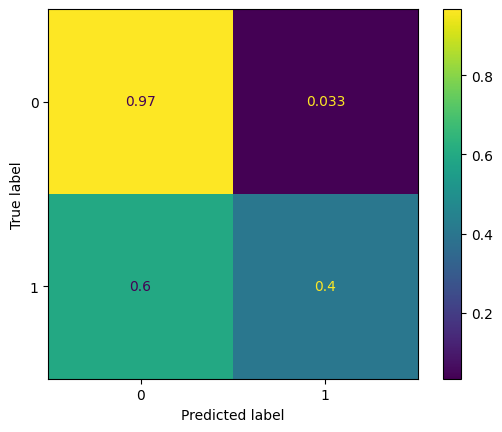

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm = confusion_matrix(y_val, xg_y_model, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
print(cm)
disp.plot()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {'min_child_weight': [8, 10, 12],'gamma':[0.5,1], 'subsample':[0.6,0.8,1.0], 'max_depth':[3,5]}

my_xgb_model = GridSearchCV(xg_model, param_grid, n_jobs=-1, verbose=2, cv=5)
my_xgb_model.fit(x_train,y_train)
print(my_xgb_model.best_params_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
{'gamma': 0.5, 'max_depth': 3, 'min_child_weight': 10, 'subsample': 1.0}


In [ ]:
# scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xg_model = XGBClassifier(min_child_weight=10, gamma=0.5, subsample=1.0,max_depth=3)

xg_model.fit(x_train,y_train)
y_pred = xg_model.predict(x_val)
print('error rate of the XGB classifier', 1-accuracy_score(y_val, y_pred))

error rate of the XGB classifier 0.10667233319167024


[[0.97972305 0.02027695]
 [0.63444109 0.36555891]]


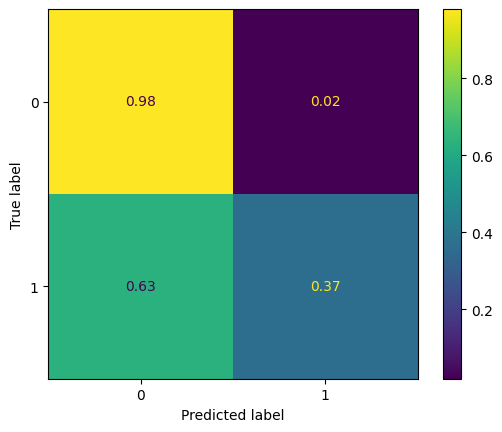

In [ ]:
cm = confusion_matrix(y_val, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
print(cm)
disp.plot()
plt.show()

In [ ]:
test.bank_account = xg_model.predict(processed_test)

submission = pd.DataFrame({'uniqueid':test['uniqueid']+" x "+test['country'],'bank_account':test.bank_account})

In [ ]:
submission.sample(5)

,uniqueid,bank_account
977,uniqueid_7046 x Kenya,1
4065,uniqueid_10200 x Rwanda,0
5840,uniqueid_11975 x Rwanda,0
4444,uniqueid_10579 x Rwanda,0
345,uniqueid_6414 x Kenya,0


In [ ]:
submission.to_csv('first_submission.csv', index=False)
files.download('first_submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(test.shape)

(10086, 12)
